# Context in Natural Language Processing


## Phase 1: Text representation

### Question

How can text be converted into numerical representations that allow a computer to compare documents?

### Objectives

1. Load a text corpus
2. Tokenize text
3. Implement Bag of Words
4. Implement TF - IDF (Term Frequency - Inverse Document Frequency)
5. Calculate cosine similarity
6. Analyze the limitations of simple text representations


In [40]:
from pathlib import Path
file_path = Path("../data/sample_texts.txt")
with open(file_path, "r") as file:
    documents = file.readlines()

documents = [doc.strip() for doc in documents if doc.strip()]

for i, document in enumerate(documents):
    print(f"Document {i + 1}: {document}")

Document 1: The cat sat on the mat.
Document 2: The dog sat beside the cat.
Document 3: The bank approved the loan.
Document 4: She deposited money in the bank.
Document 5: They sat on the bank of the river.
Document 6: The river flowed beside the bank.
Document 7: Machine learning models learn patterns from data.
Document 8: Deep learning is a branch of machine learning.


In [41]:
import re

def tokenize(text):
    text = text.lower()
    tokens = re.findall(r"\b\w+\b", text)
    return tokens

sentence = documents[0]

tokens = tokenize(sentence)

print("Original sentence:")
print(sentence)
print("\nTokens:")
print(tokens)

Original sentence:
The cat sat on the mat.

Tokens:
['the', 'cat', 'sat', 'on', 'the', 'mat']


In [42]:
#Building a vocabulary: collection of unique words in our corpus.
vocabulary = set()
for document in documents:
    tokens = tokenize(document)
    vocabulary.update(tokens)

vocabulary = sorted(vocabulary)

print(vocabulary)
print(f"\nVocabulary size: {len(vocabulary)}")

['a', 'approved', 'bank', 'beside', 'branch', 'cat', 'data', 'deep', 'deposited', 'dog', 'flowed', 'from', 'in', 'is', 'learn', 'learning', 'loan', 'machine', 'mat', 'models', 'money', 'of', 'on', 'patterns', 'river', 'sat', 'she', 'the', 'they']

Vocabulary size: 29


In [43]:
#creating an index of the words
word_to_index = {
    word: index for index, word in enumerate(vocabulary)
    }
print(word_to_index)

{'a': 0, 'approved': 1, 'bank': 2, 'beside': 3, 'branch': 4, 'cat': 5, 'data': 6, 'deep': 7, 'deposited': 8, 'dog': 9, 'flowed': 10, 'from': 11, 'in': 12, 'is': 13, 'learn': 14, 'learning': 15, 'loan': 16, 'machine': 17, 'mat': 18, 'models': 19, 'money': 20, 'of': 21, 'on': 22, 'patterns': 23, 'river': 24, 'sat': 25, 'she': 26, 'the': 27, 'they': 28}


In [44]:
#implementing a Bag-of-Words (BoW) representation
import numpy as np

def bag_of_words(text, word_to_index):
    tokens = tokenize(text)

    vector = np.zeros(len(word_to_index), dtype=int)

    for token in tokens:
        if token in word_to_index:
            index = word_to_index[token]
            vector[index] += 1

    return vector

sentence = "The dog sat"

vector = bag_of_words(sentence, word_to_index)

print("Vocabulary:")
print(vocabulary)

print("\nSentence:")
print(sentence)

print("\nBag-of-Words Vector:")
print(vector)

Vocabulary:
['a', 'approved', 'bank', 'beside', 'branch', 'cat', 'data', 'deep', 'deposited', 'dog', 'flowed', 'from', 'in', 'is', 'learn', 'learning', 'loan', 'machine', 'mat', 'models', 'money', 'of', 'on', 'patterns', 'river', 'sat', 'she', 'the', 'they']

Sentence:
The dog sat

Bag-of-Words Vector:
[0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0]


In [45]:
#matrix to represent all documents in the corpus
bow_matrix = []

for document in documents:
    vector = bag_of_words(document, word_to_index)
    bow_matrix.append(vector)

bow_matrix = np.array(bow_matrix)

print("Shape:", bow_matrix.shape)
print(bow_matrix)

Shape: (8, 29)
[[0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 2 0]
 [0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 2 0]
 [0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 2 0]
 [0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0]
 [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 2 1]
 [0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 2 0]
 [0 0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 1 0 0 0 1 0 0 0 0 0]
 [1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 2 0 1 0 0 0 1 0 0 0 0 0 0 0]]


## TF-IDF
Bag of Words treats all words as equally important.
TF-IDF improves this by assigning higher importance to words that occur frequently in a document but rarely across the entire corpus.

In [46]:
import math

def calculate_idf(documents, vocabulary):
    total_documents = len(documents)
    idf = {}

    for word in vocabulary:
        document_frequency = 0

        for document in documents:
            tokens = tokenize(document)
            if word in tokens:
                document_frequency += 1

        idf[word] = math.log(total_documents / (document_frequency + 1))

    return idf

idf_scores = calculate_idf(documents, vocabulary)
for word, score in idf_scores.items():
    print(f"Word: {word}, IDF: {score:.3f}")

Word: a, IDF: 1.386
Word: approved, IDF: 1.386
Word: bank, IDF: 0.470
Word: beside, IDF: 0.981
Word: branch, IDF: 1.386
Word: cat, IDF: 0.981
Word: data, IDF: 1.386
Word: deep, IDF: 1.386
Word: deposited, IDF: 1.386
Word: dog, IDF: 1.386
Word: flowed, IDF: 1.386
Word: from, IDF: 1.386
Word: in, IDF: 1.386
Word: is, IDF: 1.386
Word: learn, IDF: 1.386
Word: learning, IDF: 0.981
Word: loan, IDF: 1.386
Word: machine, IDF: 0.981
Word: mat, IDF: 1.386
Word: models, IDF: 1.386
Word: money, IDF: 1.386
Word: of, IDF: 0.981
Word: on, IDF: 0.981
Word: patterns, IDF: 1.386
Word: river, IDF: 0.981
Word: sat, IDF: 0.693
Word: she, IDF: 1.386
Word: the, IDF: 0.134
Word: they, IDF: 1.386


In [47]:
# Calculating term frequency
def calculate_tf(text):
    tokens = tokenize(text)
    total_words = len(tokens)

    tf = {}
    for word in tokens:
        tf[word] = tf.get(word, 0) + 1

    # Normalize TF values
    for word in tf:
        tf[word] /= total_words

    return tf

sentence = "The cat sat on the mat"

tf_scores = calculate_tf(sentence)

print(tf_scores)

{'the': 0.3333333333333333, 'cat': 0.16666666666666666, 'sat': 0.16666666666666666, 'on': 0.16666666666666666, 'mat': 0.16666666666666666}


In [48]:
def calculate_tfidf(text, word_to_index, idf_scores):
    tf_scores = calculate_tf(text)

    vector = np.zeros(len(word_to_index))

    for word, tf_value in tf_scores.items():
        if word in word_to_index:
            index = word_to_index[word]
            tfidf_value = tf_value * idf_scores[word]
            vector[index] = tfidf_value

    return vector

tfidf_vector = calculate_tfidf(
    documents[0],
    word_to_index,
    idf_scores)

for word, index in word_to_index.items():
    if tfidf_vector[index] > 0:
        print(f"Word: {word}, TF-IDF: {tfidf_vector[index]:.3f}")


Word: cat, TF-IDF: 0.163
Word: mat, TF-IDF: 0.231
Word: on, TF-IDF: 0.163
Word: sat, TF-IDF: 0.116
Word: the, TF-IDF: 0.045


### Cosine Similarity
This is used to quantify semantic similarity between documents. It is calculated by measuring the angle between vectors. If the value is close to 1, then the documents are very similar while if the value is close to 0, then the documents are not similar.

In [49]:
#Cosine similarity function
def cosine_similarity(vector_a, vector_b):
    dot_product = np.dot(vector_a, vector_b)
    magnitude_a = np.linalg.norm(vector_a)
    magnitude_b = np.linalg.norm(vector_b)

    if magnitude_a == 0 or magnitude_b == 0:
        return 0

    return dot_product / (magnitude_a * magnitude_b)

tfidf_matrix = []

for document in documents:
    vector = calculate_tfidf(document, word_to_index, idf_scores)
    tfidf_matrix.append(vector)

tfidf_matrix = np.array(tfidf_matrix)

print(tfidf_matrix.shape)

doc_1 = tfidf_matrix[0]
doc_2 = tfidf_matrix[1]

similarity = cosine_similarity(doc_1, doc_2)
print(f"Similarity between document 1 and 2: {similarity:.3f}")

doc_3 = tfidf_matrix[2]

similarity = cosine_similarity(doc_1, doc_3)
print(f"Similarity between document 1 and 3: {similarity:.3f}")

(8, 29)
Similarity between document 1 and 2: 0.344
Similarity between document 1 and 3: 0.017


In [50]:
num_documents = len(documents)

similarity_matrix = np.zeros((num_documents, num_documents))

for i in range(num_documents):
    for j in range(num_documents):
        similarity_matrix[i][j] = cosine_similarity(tfidf_matrix[i], tfidf_matrix[j])

print(similarity_matrix)

[[1.         0.34423047 0.01672378 0.00604033 0.30557645 0.01671926
  0.         0.        ]
 [0.34423047 1.         0.01672378 0.00604033 0.11138158 0.24223509
  0.         0.        ]
 [0.01672378 0.01672378 1.         0.04481134 0.0608271  0.07063768
  0.         0.        ]
 [0.00604033 0.00604033 0.04481134 1.         0.03857723 0.04479921
  0.         0.        ]
 [0.30557645 0.11138158 0.0608271  0.03857723 1.         0.26100305
  0.         0.11100298]
 [0.01671926 0.24223509 0.07063768 0.04479921 0.26100305 1.
  0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  1.         0.23164445]
 [0.         0.         0.         0.         0.11100298 0.
  0.23164445 1.        ]]


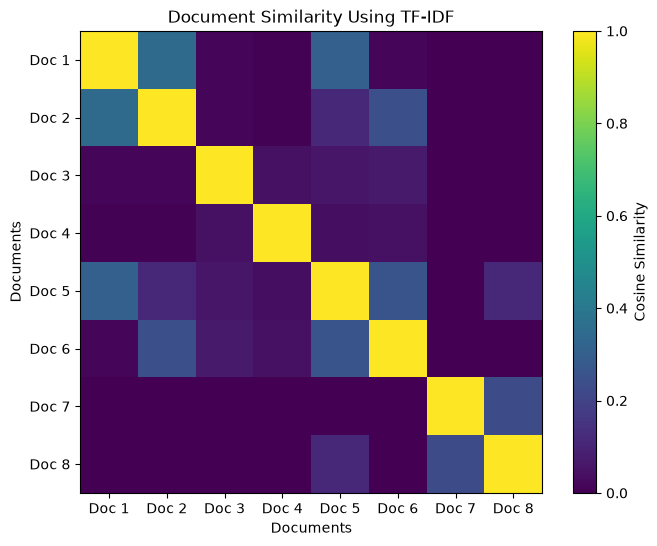

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(similarity_matrix)
plt.colorbar(label='Cosine Similarity')
plt.xticks(range(num_documents), [f'Doc {i+1}' for i in range(num_documents)])
plt.yticks(range(num_documents), [f'Doc {i+1}' for i in range(num_documents)])

plt.title("Document Similarity Using TF-IDF")
plt.xlabel("Documents")
plt.ylabel("Documents")

plt.show()

### Findings and Limitations

#### What Bag of Words and TF-IDF can do

- Convert text into numerical vectors.
- Measure word frequency
- Identify important words
- Compare documents using mathematical similarity

#### Limitations
- They do not understand semantic 
- They treat identical words as identical concepts
- They ignore deeper context
- They struggle with synonyms
- They cannot distinguish different meanings of ambiguous words
For example, "The bank approved the loan" and "They sat on the bank of the river", both contain the same token "bank", but TF-IDF cannot determine that the word has different meanings in each context.

## Phase 2: Static Word Embeddings

### Question
How can a computer represent the meaning/relationships of words as vectors?

### Objectives
- Understand vectors and semantic space
- Use pretrained embeddings
- Visualize word relationships
- Understand Word2Vec: including how it learns embeddings

In [52]:
import gensim.downloader as api

# This downloads a pre-trained model. It has been trained from a large numebr of text.
#  The 50 means that each word is represented by 50 words in a matrix
model = api.load("glove-wiki-gigaword-50") 

vector = model['cat']

print(vector)
print(vector.shape)

[ 0.45281  -0.50108  -0.53714  -0.015697  0.22191   0.54602  -0.67301
 -0.6891    0.63493  -0.19726   0.33685   0.7735    0.90094   0.38488
  0.38367   0.2657   -0.08057   0.61089  -1.2894   -0.22313  -0.61578
  0.21697   0.35614   0.44499   0.60885  -1.1633   -1.1579    0.36118
  0.10466  -0.78325   1.4352    0.18629  -0.26112   0.83275  -0.23123
  0.32481   0.14485  -0.44552   0.33497  -0.95946  -0.097479  0.48138
 -0.43352   0.69455   0.91043  -0.28173   0.41637  -1.2609    0.71278
  0.23782 ]
(50,)


In [53]:
#model.most_similar('cat')
model.most_similar('bank')

[('banks', 0.869862973690033),
 ('securities', 0.7996813654899597),
 ('banking', 0.7965160012245178),
 ('investment', 0.7849708199501038),
 ('exchange', 0.7808825969696045),
 ('financial', 0.7670274972915649),
 ('credit', 0.764915406703949),
 ('lender', 0.7518407702445984),
 ('capital', 0.7380707859992981),
 ('brokerage', 0.7373986840248108)]

In [54]:
# The relationship between the words
model.similarity('bank', 'river')

np.float32(0.4142035)

In [55]:
model["bank"]

array([ 0.66488 , -0.11391 ,  0.67844 ,  0.17951 ,  0.6828  , -0.47787 ,
       -0.30761 ,  0.17489 , -0.70512 , -0.55022 ,  0.1514  ,  0.10214 ,
       -0.45063 , -0.33069 ,  0.056133,  1.2271  ,  0.55607 , -0.68297 ,
        0.037364,  0.70266 ,  1.9093  , -0.61483 , -0.83329 , -0.3023  ,
       -1.1118  , -1.55    ,  0.2604  ,  0.22957 , -1.0375  , -0.31789 ,
        3.5091  , -0.25871 ,  1.0151  ,  0.65927 , -0.18231 , -0.75859 ,
       -0.30927 , -0.91678 ,  1.0633  , -0.66761 , -0.37464 , -0.29143 ,
        0.65606 , -0.44642 , -0.075495, -1.0552  , -0.60501 ,  0.73582 ,
        1.0139  , -0.27749 ], dtype=float32)

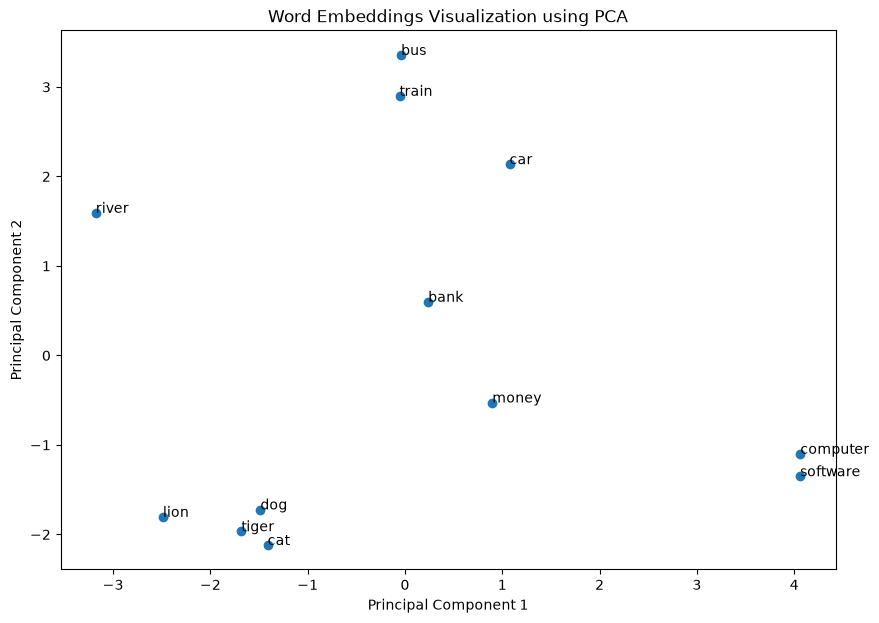

In [56]:
#Visualizing the word embeddings using PCA
words = [
    "cat",
    "dog",
    "lion",
    "tiger",
    "car",
    "bus",
    "train",
    "computer",
    "software",
    "bank",
    "money",
    "river"
]

vectors = [model[word] for word in words]


from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

#Plotting the 2D representation of the word embeddings
plt.figure(figsize=(10, 7))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]))

plt.title("Word Embeddings Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [57]:
sentence_a = "The bank approved my loan."
sentence_b = "The fisherman sat on the bank of the river."

bank_a = model["bank"]
bank_b = model["bank"]

print("Sentence A vector shape:", bank_a.shape)
print("Sentence B vector shape:", bank_b.shape)

print("Are the vectors identical?",
      (bank_a == bank_b).all())

Sentence A vector shape: (50,)
Sentence B vector shape: (50,)
Are the vectors identical? True


With GloVe we can see that a word has the exact same vector regardless of the sentence meaning because the model refers to the same vector for both sentences.

## Phase 3: Contextual Embeddings
### Question
Can we make the representation of a word change depending on the words around it?

For this, we will use BERT (transformer based model), in order to produce contextual embeddings.

In [58]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
model = AutoModel.from_pretrained('bert-base-uncased')

model.eval()

sentence_a = "The bank approved my loan."
tokens_a = tokenizer(sentence_a)

print(tokens_a)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 266.31it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'input_ids': [101, 1996, 2924, 4844, 2026, 5414, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [59]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert_model = AutoModel.from_pretrained("bert-base-uncased")

bert_model.eval()

print("BERT loaded successfully!")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 487.13it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT loaded successfully!


In [60]:
sentence_a = "The bank approved my loan."
sentence_b = "The fisherman sat on the bank of the river."

inputs_a = tokenizer(sentence_a, return_tensors="pt")
inputs_b = tokenizer(sentence_b, return_tensors="pt")

tokens_a = tokenizer.convert_ids_to_tokens(inputs_a["input_ids"][0])
tokens_b = tokenizer.convert_ids_to_tokens(inputs_b["input_ids"][0])

print("Sentence A:", tokens_a)
print("Sentence B:", tokens_b)

Sentence A: ['[CLS]', 'the', 'bank', 'approved', 'my', 'loan', '.', '[SEP]']
Sentence B: ['[CLS]', 'the', 'fisherman', 'sat', 'on', 'the', 'bank', 'of', 'the', 'river', '.', '[SEP]']


In [61]:
inputs_a = tokenizer(
    sentence_a,
    return_tensors="pt"
)

print(inputs_a)

{'input_ids': tensor([[ 101, 1996, 2924, 4844, 2026, 5414, 1012,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1]])}


In [62]:
with torch.no_grad():
    outputs_a = bert_model(**inputs_a)
    outputs_b = bert_model(**inputs_b)

print("Sentence A output shape:", outputs_a.last_hidden_state.shape)
print("Sentence B output shape:", outputs_b.last_hidden_state.shape)

Sentence A output shape: torch.Size([1, 8, 768])
Sentence B output shape: torch.Size([1, 12, 768])


In [63]:
bank_position_a = tokens_a.index("bank")
bank_position_b = tokens_b.index("bank")

print("Bank position in A:", bank_position_a)
print("Bank position in B:", bank_position_b)

Bank position in A: 2
Bank position in B: 6


In [64]:
bank_vector_a = outputs_a.last_hidden_state[0, bank_position_a]
bank_vector_b = outputs_b.last_hidden_state[0, bank_position_b]

print("Bank vector A:", bank_vector_a.shape)
print("Bank vector B:", bank_vector_b.shape)

Bank vector A: torch.Size([768])
Bank vector B: torch.Size([768])


In [65]:
import torch.nn.functional as F

similarity = F.cosine_similarity(
    bank_vector_a.unsqueeze(0),
    bank_vector_b.unsqueeze(0)
)

difference = torch.norm(bank_vector_a - bank_vector_b)

print("Cosine similarity:", similarity.item())
print("Vector difference:", difference.item())

Cosine similarity: 0.4184335470199585
Vector difference: 16.357219696044922


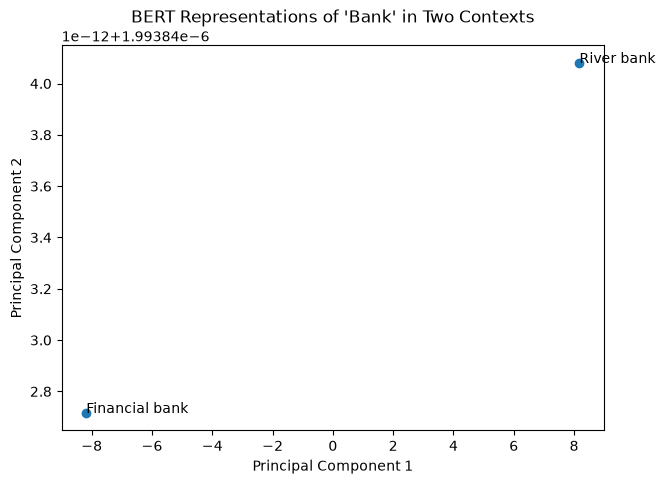

In [66]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np

bank_vectors = torch.stack([
    bank_vector_a,
    bank_vector_b
]).cpu().numpy()

pca = PCA(n_components=2)
bank_vectors_2d = pca.fit_transform(bank_vectors)

plt.figure(figsize=(7, 5))

plt.scatter(
    bank_vectors_2d[:, 0],
    bank_vectors_2d[:, 1]
)

labels = [
    "Financial bank",
    "River bank"
]

for i, label in enumerate(labels):
    plt.annotate(
        label,
        (bank_vectors_2d[i, 0], bank_vectors_2d[i, 1])
    )

plt.title("BERT Representations of 'Bank' in Two Contexts")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

## Phase 4: Build Self Attention from Scratch
### Research Question
How does a model decide which other words to use when building a token's representation?


In [67]:
import numpy as np

tokens = ["The", "animal", "crossed", "road"]

X = np.array([
    [1.0, 0.0, 1.0, 0.0],
    [0.0, 2.0, 0.0, 2.0],
    [1.0, 1.0, 0.0, 1.0],
    [0.0, 1.0, 1.0, 0.0]
])

print("Input matrix shape:", X.shape)
print(X)

Input matrix shape: (4, 4)
[[1. 0. 1. 0.]
 [0. 2. 0. 2.]
 [1. 1. 0. 1.]
 [0. 1. 1. 0.]]


In [68]:
np.random.seed(42)

W_Q = np.random.rand(4, 3)
W_K = np.random.rand(4, 3)
W_V = np.random.rand(4, 3)

Q = X @ W_Q
K = X @ W_K
V = X @ W_V

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: (4, 3)
K shape: (4, 3)
V shape: (4, 3)


In [69]:
scores = Q @ K.T

print("Attention scores:")
print(np.round(scores, 3))

Attention scores:
[[2.52  4.822 3.4   2.863]
 [5.27  6.122 5.721 4.378]
 [4.168 5.742 4.848 3.818]
 [1.946 2.993 2.398 1.873]]


In [70]:
scaled_scores = scores / np.sqrt(K.shape[1])

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

attention_weights = softmax(scaled_scores)

print("Attention weights:")
print(np.round(attention_weights, 3))

print("Row sums:")
print(attention_weights.sum(axis=1))

Attention weights:
[[0.131 0.493 0.217 0.159]
 [0.221 0.361 0.286 0.132]
 [0.173 0.429 0.256 0.141]
 [0.197 0.36  0.255 0.189]]
Row sums:
[1. 1. 1. 1.]


In [71]:
contextual_output = attention_weights @ V

print("Contextual output shape:", contextual_output.shape)
print(np.round(contextual_output, 3))

Contextual output shape: (4, 3)
[[2.177 2.292 1.124]
 [1.989 2.108 0.992]
 [2.091 2.211 1.066]
 [1.963 2.051 0.957]]


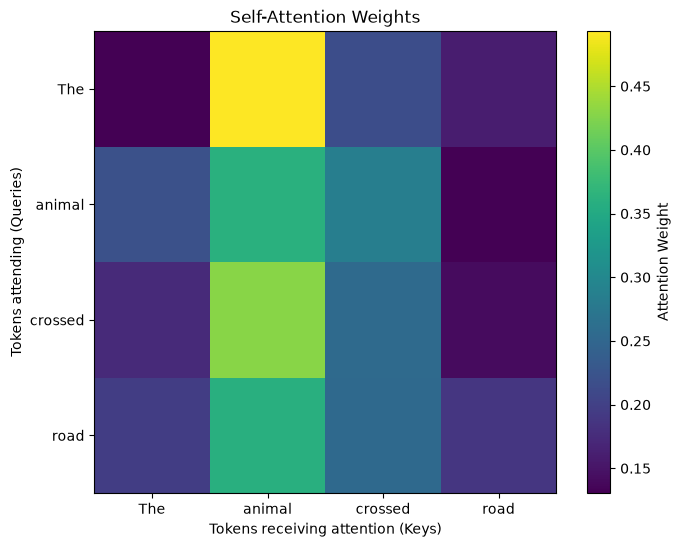

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(attention_weights)

plt.colorbar(label="Attention Weight")

plt.xticks(
    range(len(tokens)),
    tokens
)

plt.yticks(
    range(len(tokens)),
    tokens
)

plt.xlabel("Tokens receiving attention (Keys)")
plt.ylabel("Tokens attending (Queries)")

plt.title("Self-Attention Weights")

plt.show()

In [73]:
for i, token in enumerate(tokens):
    print(f"\nAttention from '{token}':")

    for j, other_token in enumerate(tokens):
        print(
            f"  {other_token}: "
            f"{attention_weights[i][j]:.4f}"
        )


Attention from 'The':
  The: 0.1306
  animal: 0.4933
  crossed: 0.2169
  road: 0.1592

Attention from 'animal':
  The: 0.2207
  animal: 0.3611
  crossed: 0.2864
  road: 0.1319

Attention from 'crossed':
  The: 0.1731
  animal: 0.4293
  crossed: 0.2562
  road: 0.1414

Attention from 'road':
  The: 0.1966
  animal: 0.3597
  crossed: 0.2552
  road: 0.1885


In [74]:
print("Original contextual output:")
print(np.round(contextual_output, 3))

Original contextual output:
[[2.177 2.292 1.124]
 [1.989 2.108 0.992]
 [2.091 2.211 1.066]
 [1.963 2.051 0.957]]


In [75]:
X_modified = X.copy()

X_modified[1] = [2.0, 0.0, 1.0, 1.0]

In [76]:
Q_modified = X_modified @ W_Q
K_modified = X_modified @ W_K
V_modified = X_modified @ W_V

scores_modified = Q_modified @ K_modified.T

scaled_modified = scores_modified / np.sqrt(K_modified.shape[1])

attention_modified = softmax(scaled_modified)

output_modified = attention_modified @ V_modified

print("Modified contextual output:")
print(np.round(output_modified, 3))

Modified contextual output:
[[1.917 2.049 0.885]
 [2.232 2.437 1.114]
 [2.127 2.308 1.038]
 [1.874 1.994 0.853]]


In [77]:
print(
    "Total output difference:",
    np.linalg.norm(contextual_output - output_modified)
)

Total output difference: 0.63244884613595
